### Config

In [1]:
# adding project root
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
import os, json, time, shutil, tempfile, subprocess, sys, traceback
import requests, importlib.util
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src.settings import tiingo_api, RAW, PRIVATE, ROOT, WS

TICKERS = ["SPY","QQQ","IWM","XLE","XLF","XLK","XLV","XLP","XLY"]
START, END = "2004-01-01", "2025-12-31"


### Fetch and Format Data

#### Prep research data

In [3]:
def fetch_tiingo(symbol: str, start: str = START, end: str = END):
    """Fetch daily data from Tiingo API"""
    headers = {
        "Content-Type": "application/json",
        "Authorization": f"Token {tiingo_api}"
    }
    params = {"startDate": start, "endDate": end, "format": "json"}
    r = requests.get(f"https://api.tiingo.com/tiingo/daily/{symbol}/prices", headers=headers, params=params, timeout=60)
    return r.json()

for s in TICKERS:
    f = RAW / f"{s}.json"
    if not f.exists():
        f.write_text(json.dumps(fetch_tiingo(s)))
        time.sleep(0.3)

pd.DataFrame([
    {
    "symbol": s, 
    "rows": len(j := json.loads((RAW/f"{s}.json").read_text())), 
    "first": j[0]["date"], 
    "last": j[-1]["date"]
    } for s in TICKERS ])


,symbol,rows,first,last
0,SPY,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
1,QQQ,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
2,IWM,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
3,XLE,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
4,XLF,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
5,XLK,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
6,XLV,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
7,XLP,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z
8,XLY,5535,2004-01-02T00:00:00.000Z,2025-12-31T00:00:00.000Z


#### Check data for discrepancies

In [4]:
def to_frame(symbol) -> pd.DataFrame:
    df = pd.DataFrame(json.loads((RAW/f"{symbol}.json").read_text()))
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None)
    # Map Tiingo's 'adjClose' to EODHD's 'adjusted_close' (will be updated to use just 'adj_close soon)
    if "adjClose" in df.columns and "adjusted_close" not in df.columns:
        df = df.rename(columns={"adjClose": "adjusted_close"})
    return df.set_index("date").sort_index()[["close", "adjusted_close", "volume"]].astype(float)

frames, report = {}, []
for s in TICKERS:
    d = to_frame(s)
    report.append({
        "symbol": s,
        "rows": len(d),
        "duplicate_dates": int(d.index.duplicated().sum()),
        "missing": int(d.isna().sum().sum()),
        "nonpositive_price": int((d[["close", "adjusted_close"]] <= 0).sum().sum()),
        "zero_volume_days": int((d["volume"] <= 0).sum())
    })
    frames[s] = d[~d.index.duplicated(keep="last")]

pd.DataFrame(report)


,symbol,rows,duplicate_dates,missing,nonpositive_price,zero_volume_days
0,SPY,5535,0,0,0,0
1,QQQ,5535,0,0,0,0
2,IWM,5535,0,0,0,0
3,XLE,5535,0,0,0,0
4,XLF,5535,0,0,0,0
5,XLK,5535,0,0,0,0
6,XLV,5535,0,0,0,0
7,XLP,5535,0,0,0,0
8,XLY,5535,0,0,0,0


#### Align Histories by Trading Date and Create 3 research periods.

In [5]:
def panel(field):
    return pd.concat({s: frames[s][field] for s in TICKERS}, axis=1)[TICKERS]

adj_close = panel("adjusted_close").dropna()
close = panel("close").loc[adj_close.index]
volume = panel("volume").loc[adj_close.index]
returns = adj_close.pct_change().fillna(0.0)

SPLITS = {
    "dev": ("2005-01-01","2017-12-31"),
    "val": ("2018-01-01","2021-12-31"),
    "holdout": ("2022-01-01","2025-12-31")
    }

WARMUP = 250

def make_split(name):
    lo, hi = SPLITS[name]; idx = adj_close.index
    first = idx[max(0, idx.searchsorted(pd.Timestamp(lo)) - WARMUP)]
    keep = (idx >= first) & (idx <= pd.Timestamp(hi))
    return {
        "adj_close": adj_close[keep],
        "close": close[keep],
        "volume": volume[keep],
        "returns": returns[keep],
        "eval_start": pd.Timestamp(lo)
    }

DATA = {name: make_split(name) for name in SPLITS}

for name in ["dev","val"]:
    for field in ["adj_close","close","volume"]:
        DATA[name][field].to_parquet(WS/"data"/f"{name}_{field}.parquet")
json.dump({k: v[0] for k,v in SPLITS.items()}, open(WS/"data"/"splits.json","w"))

DELETE_RAW_CACHE = False
if DELETE_RAW_CACHE:
    shutil.rmtree(RAW, ignore_errors=True)

print("holdout files on disk:", list(ROOT.rglob("holdout*")) or "NONE")
pd.DataFrame({
    n: {
        "rows": len(DATA[n]["adj_close"]), "eval_start": DATA[n]["eval_start"].date(),
        "end": DATA[n]["adj_close"].index[-1].date()
        } for n in SPLITS
    }).T

holdout files on disk: NONE


,rows,eval_start,end
dev,3522,2005-01-01,2017-12-29
val,1258,2018-01-01,2021-12-31
holdout,1253,2022-01-01,2025-12-31


#### Clear previous run artifacts before research run

In [6]:
for d in [WS/"strategies", WS/"results", WS/"reviews", PRIVATE]:
    shutil.rmtree(d, ignore_errors=True)
    d.mkdir(parents=True, exist_ok=True)

for f in [WS/"registry.csv", WS/"decisions.jsonl", WS/"report.md", WS/"frozen.json", WS/"strategies"/"frozen.json"]:
    f.unlink(missing_ok=True)

for f in WS.glob("data/holdout_*.parquet"):
    f.unlink()

print("private:", list(PRIVATE.iterdir()) or 'empty')
print("holdout on disk:", list(ROOT.rglob('holdout*')) or "NONE")
print("workspace reset")

private: empty
holdout on disk: NONE
workspace reset


### Build Deterministic Evaluation Layer

#### Create Shared Backtesting Engine

In [7]:
ENGINE = '''
"""Fixed backtest engine and standard metrics. Imported by the notebook AND by the isolated runner, so both compute identical numbers from identical code."""
import json
import numpy as np, pandas as pd
from pathlib import Path

PERIODS, RF_ANNUAL, MAR_ANNUAL = 252, 0.0, 0.0

def backtest(weights, returns, cost_bps=10.0):
    scheduled = pd.Series(returns.index.isin(weights.index), index=returns.index, dtype=bool)
    w = weights.reindex(returns.index).ffill().shift(1).fillna(0.0)
    is_rebal = scheduled.shift(1, fill_value=False)

    held = pd.Series(0.0, index=returns.columns)
    rows = []

    for d in returns.index:
        target = w.loc[d] if is_rebal.loc[d] else held
        traded = float((target - held).abs().sum())
        cost = traded * cost_bps / 1e4

        r = returns.loc[d]
        gross = float((target*r).sum())
        net = gross - cost

        rows.append((net, traded, cost, float(1.0 - target.sum())))

        denominator = 1.0 + gross
        if denominator <= 0:
            raise RuntimeError(f"Gross portfolio value became non-positive on {d}: gross return = {gross}")

        held = (target * (1.0 + r)) / denominator

    return pd.DataFrame(rows, index=returns.index, columns=["ret", "turnover", "cost", "cash"])

def metrics(bt, benchmark=None, rf_annual=RF_ANNUAL, mar_annual=MAR_ANNUAL):
    r = bt["ret"]
    rf_d = (1 + rf_annual) ** (1/PERIODS) - 1
    mar_d = (1 + mar_annual) ** (1/PERIODS) - 1
    ex = r - rf_d
    eq = (1 + r).cumprod(); yrs = len(r)/PERIODS
    sd = ex.std(ddof=1)
    dd = np.sqrt((np.minimum(r - mar_d, 0.0) ** 2).mean()) * np.sqrt(PERIODS)
    m = {"cagr": eq.iloc[-1] ** (1/yrs) - 1,
         "ann_ret": r.mean() * PERIODS,
         "vol": r.std(ddof=1) * np.sqrt(PERIODS),
         "sharpe": (ex.mean()/sd) * np.sqrt(PERIODS) if sd > 0 else 0.0,
         "sortino": (r.mean()*PERIODS - mar_annual)/dd if dd > 0 else 0.0,
         "max_dd": (eq/eq.cummax() - 1).min(),
         "ann_turnover": bt["turnover"].sum()/yrs,
         "ann_cost": bt["cost"].sum()/yrs,
         "avg_cash": bt["cash"].mean()}
    if benchmark is not None:
        m["bench_cagr"] = (1+benchmark).cumprod().iloc[-1] ** (1/yrs) - 1
    return {k: round(float(v), 4) for k, v in m.items()}

def load_split(data_dir, split):
    p = Path(data_dir)
    d = {f: pd.read_parquet(p/f"{split}_{f}.parquet") for f in ["adj_close","close","volume"]}
    d["returns"] = d["adj_close"].pct_change().fillna(0.0)
    d["eval_start"] = pd.Timestamp(json.load(open(p/"splits.json"))[split])
    return d
    '''

(ROOT/"engine.py").write_text(ENGINE)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import engine
importlib.reload(engine)
from engine import backtest, metrics
print("engine.py has been written!")

engine.py has been written!


#### Verify Portfolio Accounting

In [8]:
w = pd.DataFrame(0.0, index=[DATA["dev"]["adj_close"].index[0]], columns=TICKERS)
w.iloc[0, 0] = 1.0
assert round(backtest(w, DATA["dev"]["returns"]).turnover.sum(), 4) == 1.0
print("turnover check ok")

turnover check ok


#### Establish Fixed Benchmarks

In [9]:
def bh_weights(data, tickers):
    w = pd.DataFrame(0.0, index=[data["adj_close"].index[0]], columns=data["adj_close"].columns)
    w.loc[w.index[0], tickers] = 1.0/len(tickers)
    return w

def plain_momentum(data, mom_window=126, top_n=3):
    adj = data["adj_close"]; mom = adj.pct_change(mom_window)
    dates = pd.DatetimeIndex(adj.index.to_series().resample("ME").last().dropna())
    w = pd.DataFrame(0.0, index=dates, columns=adj.columns)
    for dt in dates:
        picks = mom.loc[dt][mom.loc[dt] > 0].dropna().nlargest(top_n).index
        if len(picks): w.loc[dt, picks] = 1.0/len(picks)
    return w

def volume_momentum(data, mom_window=126, top_n=3, vol_short=20, vol_long=120, vol_ratio_min=1.0):
    adj, cls, vol = data["adj_close"], data["close"], data["volume"]
    mom = adj.pct_change(mom_window); dv = cls*vol
    ratio = dv.rolling(vol_short).mean()/dv.rolling(vol_long).mean()
    ok = (mom > 0) & (ratio > vol_ratio_min)
    dates = pd.DatetimeIndex(adj.index.to_series().resample("ME").last().dropna())
    w = pd.DataFrame(0.0, index=dates, columns=adj.columns)
    for dt in dates:
        picks = mom.loc[dt][ok.loc[dt]].dropna().nlargest(top_n).index
        if len(picks): w.loc[dt, picks] = 1.0/len(picks)
    return w

BENCHMARKS = {"spy_bh": lambda d: bh_weights(d, ["SPY"]),
              "ew_bh": lambda d: bh_weights(d, TICKERS),
              "plain_mom": plain_momentum, "volume_mom": volume_momentum}

def benchmark_table(split):
    d = DATA[split]; rows = {}
    for name, fn in BENCHMARKS.items():
        bt = backtest(fn(d), d["returns"])
        rows[name] = metrics(bt.loc[d["eval_start"]:], d["returns"]["SPY"].loc[d["eval_start"]:])
    return pd.DataFrame(rows).T

COLS_B = ["cagr","sharpe","sortino","max_dd","ann_turnover"]
BENCH = {s: benchmark_table(s) for s in ["dev","val"]}
BENCH_TEXT = ("DEVELOPMENT\n" + BENCH["dev"][COLS_B].to_string() +
              "\n\nVALIDATION\n" + BENCH["val"][COLS_B].to_string())
(WS/"BENCHMARKS.md").write_text("# Fixed benchmarks\n\n```\n" + BENCH_TEXT + "\n```\n")

ab = BENCH["dev"].loc["volume_mom"] - BENCH["dev"].loc["plain_mom"]
print(BENCH["dev"][COLS_B])
print(f"\nvolume filter effect on dev: sharpe {ab['sharpe']:+.4f}, "
      f"cagr {ab['cagr']:+.4f}, turnover {ab['ann_turnover']:+.2f}")

              cagr  sharpe  sortino  max_dd  ann_turnover
spy_bh      0.0847  0.5261   0.7450 -0.5520        0.0000
ew_bh       0.0904  0.5524   0.7776 -0.5205        0.0000
plain_mom   0.0752  0.5389   0.7489 -0.2827        7.2800
volume_mom  0.0639  0.4939   0.6832 -0.2564       11.7608

volume filter effect on dev: sharpe -0.0450, cagr -0.0113, turnover +4.48


#### Create Isolated Processes for Execution

In [10]:
RUNNER = '''
"""Isolated strategy runner. Own process, temp sandbox, scrubbed environment."""
import sys, json, importlib.util, traceback

def main():
    strat, params_json, data_dir, split, cost_bps = sys.argv[1:6]
    import engine
    d = engine.load_split(data_dir, split)
    spec = importlib.util.spec_from_file_location("strategy", strat)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    w = mod.target_weights(d, **json.loads(params_json))
    bt = engine.backtest(w, d["returns"], cost_bps=float(cost_bps))
    ev = bt.loc[d["eval_start"]:]
    bench = d["returns"]["SPY"].loc[d["eval_start"]:] if "SPY" in d["returns"] else None
    print(json.dumps({"ok": True, "metrics": engine.metrics(ev, bench),
                      "equity": [round(float(x), 6) for x in (1+ev["ret"]).cumprod().tolist()],
                      "dates": [str(x.date()) for x in ev.index]}))

if __name__ == "__main__":
    try: main()
    except Exception: print(json.dumps({"ok": False, "error": traceback.format_exc(limit=3)}))
'''
(ROOT/"runner.py").write_text(RUNNER)

def isolated_environment(sandbox):

    required = ["PATH","SYSTEMROOT","WINDIR","COMSPEC","PATHEXT","VIRTUAL_ENV","CONDA_PREFIX","CONDA_DEFAULT_ENV","LD_LIBRARY_PATH",
                "DYLD_LIBRARY_PATH","LANG","LC_ALL"]

    env = {name: os.environ[name] for name in required if name in os.environ}

    env.update({
        "HOME": str(sandbox),
        "USERPROFILE": str(sandbox),
        "TEMP": str(sandbox),
        "TMP": str(sandbox),
        "TMPDIR": str(sandbox),
        "PYTHONHASHSEED": "1",
        "PYTHONUTF8": "1",
    })

    return env

def run_isolated(strategy_path, params, split, cost_bps=10.0, timeout=600):
    sandbox = Path(tempfile.mkdtemp(prefix="strat_"))
    (sandbox/"data").mkdir()
    for f in ["adj_close","close","volume"]:
        shutil.copy(WS/"data"/f"{split}_{f}.parquet", sandbox/"data")
    shutil.copy(WS/"data"/"splits.json", sandbox/"data")
    shutil.copy(ROOT/"engine.py", sandbox); shutil.copy(ROOT/"runner.py", sandbox)
    shutil.copy(strategy_path, sandbox/"strategy.py")
    try:
        p = subprocess.run([sys.executable, "runner.py", "strategy.py", json.dumps(params),
                            "data", split, str(cost_bps)],
                           capture_output=True, text=True, cwd=sandbox, timeout=timeout,
                           env=isolated_environment(sandbox))
        if not p.stdout.strip():
            return {"ok": False, "error": (p.stderr or "no output")[-400:]}
        return json.loads(p.stdout)
    except subprocess.TimeoutExpired:
        return {"ok": False, "error": f"timeout after {timeout}s"}
    finally:
        shutil.rmtree(sandbox, ignore_errors=True)

#### Verify Execution Parity and Data Boundaries

In [11]:
(WS/"strategies"/"parity_check.py").write_text('''import pandas as pd
def target_weights(data, mom_window=126, top_n=3, vol_short=20, vol_long=120, vol_ratio_min=1.0):
    adj, cls, vol = data["adj_close"], data["close"], data["volume"]
    mom = adj.pct_change(mom_window); dv = cls*vol
    ratio = dv.rolling(vol_short).mean()/dv.rolling(vol_long).mean()
    ok = (mom>0)&(ratio>vol_ratio_min)
    dates = pd.DatetimeIndex(adj.index.to_series().resample("ME").last().dropna())
    w = pd.DataFrame(0.0, index=dates, columns=adj.columns)
    for d in dates:
        picks = mom.loc[d][ok.loc[d]].dropna().nlargest(top_n).index
        if len(picks): w.loc[d,picks]=1.0/len(picks)
    return w
''')
iso = run_isolated(WS/"strategies"/"parity_check.py", {"mom_window":126,"top_n":3}, "dev")
d = DATA["dev"]
inp = metrics(backtest(volume_momentum(d, 126, 3), d["returns"]).loc[d["eval_start"]:],
              d["returns"]["SPY"].loc[d["eval_start"]:])
assert iso["metrics"]["sharpe"] == inp["sharpe"], "isolated and in-process disagree"
print("parity ok:", iso["metrics"]["sharpe"])

PROBE = f'''import os, glob
def target_weights(data, **k):
    keys = [x for x in os.environ if any(t in x for t in ("KEY","TOKEN","SECRET"))]
    files = glob.glob(r"{PRIVATE}/*") + glob.glob(r"{WS}/data/holdout_*")
    raise RuntimeError(f"KEYS={{keys}} REACHABLE_SENSITIVE_FILES={{len(files)}}")
'''
(WS/"strategies"/"probe.py").write_text(PROBE)
msg = run_isolated(WS/"strategies"/"probe.py", {}, "dev")["error"].strip().split("\n")[-1]
print("probe:", msg)
assert "KEYS=[]" in msg, "credentials reachable from the sandbox"
assert "REACHABLE_SENSITIVE_FILES=0" in msg, "holdout or private files reachable from the sandbox"

parity ok: 0.4939
probe: RuntimeError: KEYS=[] REACHABLE_SENSITIVE_FILES=0


### Create Experiment and Decision Layer

#### Create Experiment Registry

In [12]:
REGISTRY = WS / "registry.csv"
DECISIONS = WS / "decisions.jsonl"
MAX_CONFIGS = 12
COLS = ["version","run","status","params","note","dev_cagr","dev_sharpe","dev_sortino",
        "dev_max_dd","dev_turnover","val_cagr","val_sharpe","val_max_dd","dev_cagr_20bps","error"]

def _used(version):
    if not REGISTRY.exists(): return 0
    return int((pd.read_csv(REGISTRY)["version"] == version).sum())

def _decisions():
    if not DECISIONS.exists(): return []
    return [json.loads(l) for l in DECISIONS.read_text().splitlines() if l.strip()]

def _stage_ok(version):
    """vN cannot begin until v(N-1) is swept, reviewed and decided."""
    if not (version.startswith("v") and version[1:].isdigit()): return True, ""
    n = int(version[1:])
    if n <= 1: return True, ""
    prev = f"v{n-1}"
    if not REGISTRY.exists() or _used(prev) == 0:
        return False, f"stage gate: {prev} has no recorded runs. Complete {prev} first."
    reg = pd.read_csv(REGISTRY)
    if reg[(reg.version == prev) & (reg.status == "ok")].empty:
        return False, f"stage gate: {prev} has no successful runs."
    if not (WS/"reviews"/f"{prev}.md").exists():
        return False, f"stage gate: /reviews/{prev}.md does not exist. Get a critic review first."
    if not any(d["version"] == prev for d in _decisions()):
        return False, f"stage gate: no decision recorded for {prev}. Call record_decision first."
    return True, ""

#### Create Research Tools

In [13]:
from langchain.tools import tool

@tool
def sweep(version: str, grid_json: str, note: str = "") -> str:
    """Backtest strategies/<version>.py over several parameter sets in ONE call.

    version   : file stem, e.g. "v1" for strategies/v1.py
    grid_json : JSON list of parameter objects, e.g. [{"top_n":3},{"top_n":4}]
    note      : short reason for this sweep

    Runs each configuration in an isolated subprocess. Returns a CSV table sorted by
    validation Sharpe. Max 12 configurations per version, cumulative. Every row is
    written to registry.csv, including failures. vN is blocked until v(N-1) is swept,
    reviewed and decided.
    """
    ok, why = _stage_ok(version)
    if not ok: return f"error: {why}"
    used = _used(version)
    try:
        grid = json.loads(grid_json)
        if isinstance(grid, dict): grid = [grid]
    except Exception as e:
        return f"error: grid_json is not valid JSON ({e})"
    if used + len(grid) > MAX_CONFIGS:
        return f"error: budget. {used}/{MAX_CONFIGS} used on {version}, you asked for {len(grid)} more."
    path = WS/"strategies"/f"{version}.py"
    if not path.exists():
        return f"error: {path.name} does not exist. Write it first."

    rows = []
    for i, params in enumerate(grid, start=used + 1):
        row = {"version": version, "run": i, "note": note,
               "params": json.dumps(params, separators=(",", ":"))}
        dev = run_isolated(path, params, "dev")
        if not dev["ok"]:
            row.update(status="error", error=dev["error"].strip().split("\n")[-1][:150])
            rows.append(row); continue
        val = run_isolated(path, params, "val")
        c20 = run_isolated(path, params, "dev", cost_bps=20.0)
        dm, vm = dev["metrics"], val["metrics"]
        row.update(status="ok", dev_cagr=dm["cagr"], dev_sharpe=dm["sharpe"],
                   dev_sortino=dm["sortino"], dev_max_dd=dm["max_dd"],
                   dev_turnover=dm["ann_turnover"], val_cagr=vm["cagr"],
                   val_sharpe=vm["sharpe"], val_max_dd=vm["max_dd"],
                   dev_cagr_20bps=c20["metrics"]["cagr"] if c20["ok"] else None)
        tag = f"{version}_run{i}"
        (WS/"results"/f"{tag}.json").write_text(json.dumps({"params": params, "dev": dm, "val": vm}, indent=2))
        eq = pd.Series(dev["equity"], index=pd.to_datetime(dev["dates"]))
        plt.figure(figsize=(8,3)); plt.plot(eq); plt.yscale("log"); plt.title(tag)
        plt.tight_layout(); plt.savefig(WS/"results"/f"{tag}.png", dpi=90); plt.close("all")
        rows.append(row)

    df = pd.DataFrame(rows).reindex(columns=COLS)
    df.to_csv(REGISTRY, mode="a", header=not REGISTRY.exists(), index=False)
    out = df.drop(columns=["version","note"]).round(3).dropna(axis=1, how="all")
    if "val_sharpe" in out:
        out = out.sort_values("val_sharpe", ascending=False, na_position="last")
    return out.to_csv(index=False)

@tool
def read_registry(version: str = "") -> str:
    """Every run recorded so far as CSV, accepted and rejected. Pass a version to filter."""
    if not REGISTRY.exists(): return "empty"
    r = pd.read_csv(REGISTRY)
    if version: r = r[r["version"] == version]
    return r[["version","run","status","params","dev_sharpe","dev_sortino",
              "dev_max_dd","val_sharpe","val_max_dd","error"]].to_csv(index=False)

@tool
def record_decision(version: str, champion: str, rationale: str, params_json: str) -> str:
    """Record the approved outcome of a version. REQUIRED before the next version can be swept.

    version    : the version just reviewed, e.g. "v2"
    champion   : which version is champion after applying the selection rule
    rationale  : cite the selection rule and the specific numbers that decided it
    params_json: the champion's parameters as JSON
    """
    if any(d["version"] == version for d in _decisions()):
        return f"error: a decision for {version} already exists and cannot be overwritten."
    rec = {"version": version, "champion": champion, "rationale": rationale,
           "params": json.loads(params_json), "ts": time.time()}
    with DECISIONS.open("a") as f:
        f.write(json.dumps(rec) + "\n")
    return f"recorded. champion is now {champion}"

#### Fix Strategy Selection Rule

In [14]:
SELECTION_RULE = """
# Version selection rule (fixed before any version was run)

A challenger replaces the incumbent champion only if it passes ALL THREE gates:

1. Validation Sharpe is not worse than the incumbent's
2. Validation max drawdown is within 2 percentage points of the incumbent's
3. Development annual turnover is no more than 20% above the incumbent's

Ties go to the incumbent. A newer version does not automatically replace an older one.
A higher development Sharpe is not sufficient and is not one of the gates.
"""
(WS/"SELECTION_RULE.md").write_text(SELECTION_RULE)

def select_champion(challenger, incumbent, name_c, name_i):
    if incumbent is None: return name_c, "no incumbent"
    checks = [("validation Sharpe not worse",
               challenger["val_sharpe"] >= incumbent["val_sharpe"]),
              ("validation drawdown within 2pp",
               challenger["val_max_dd"] >= incumbent["val_max_dd"] - 0.02),
              ("turnover within +20%",
               challenger["dev_turnover"] <= incumbent["dev_turnover"] * 1.20)]
    failed = [n for n, ok in checks if not ok]
    if failed:
        return name_i, "incumbent retained; challenger failed: " + "; ".join(failed)
    return name_c, "challenger passed all three gates"

def best_of(version):
    reg = pd.read_csv(REGISTRY)
    rows = reg[(reg.version == version) & (reg.status == "ok")]
    return None if rows.empty else rows.sort_values("val_sharpe", ascending=False).iloc[0]

print(SELECTION_RULE)


# Version selection rule (fixed before any version was run)

A challenger replaces the incumbent champion only if it passes ALL THREE gates:

1. Validation Sharpe is not worse than the incumbent's
2. Validation max drawdown is within 2 percentage points of the incumbent's
3. Development annual turnover is no more than 20% above the incumbent's

Ties go to the incumbent. A newer version does not automatically replace an older one.
A higher development Sharpe is not sufficient and is not one of the gates.



### Establish Manual Baseline

{'cagr': 0.0639, 'ann_ret': 0.0729, 'vol': 0.1476, 'sharpe': 0.4939, 'sortino': 0.6832, 'max_dd': -0.2564, 'ann_turnover': 11.7608, 'ann_cost': 0.0118, 'avg_cash': 0.2109, 'bench_cagr': 0.0847}


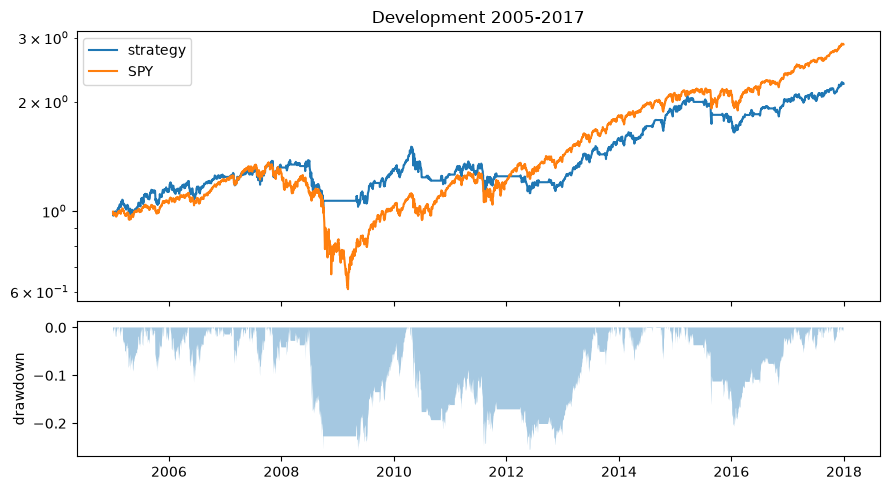

In [15]:
def manual_baseline(data, mom_window=126, vol_short=20, vol_long=120,
                    vol_ratio_min=1.0, top_n=3):
    adj, cls, vol = data["adj_close"], data["close"], data["volume"]
    mom = adj.pct_change(mom_window)
    dv = cls * vol
    ratio = dv.rolling(vol_short).mean() / dv.rolling(vol_long).mean()
    ok = (mom > 0) & (ratio > vol_ratio_min)
    dates = pd.DatetimeIndex(adj.index.to_series().resample("ME").last().dropna())
    w = pd.DataFrame(0.0, index=dates, columns=adj.columns)
    for d in dates:
        picks = mom.loc[d][ok.loc[d]].dropna().nlargest(top_n).index
        if len(picks):
            w.loc[d, picks] = 1.0 / len(picks)
    return w

d = DATA["dev"]
bt = backtest(manual_baseline(d), d["returns"])
ev = bt.loc[d["eval_start"]:]
spy = d["returns"]["SPY"].loc[d["eval_start"]:]
print(metrics(ev, spy))

fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True, height_ratios=[2, 1])
eq = (1 + ev["ret"]).cumprod()
ax[0].plot(eq, label="strategy"); ax[0].plot((1 + spy).cumprod(), label="SPY")
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title("Development 2005-2017")
ax[1].fill_between(eq.index, (eq / eq.cummax() - 1), 0, alpha=.4)
ax[1].set_ylabel("drawdown")
plt.tight_layout()
plt.show()

### Deep Agents Research Team Configuration

#### Set Agent Roles and Boundaries

In [16]:
# load_dotenv(override=True)
from deepagents import create_deep_agent, FilesystemPermission
from deepagents.backends import FilesystemBackend
from langchain.chat_models import init_chat_model
from langgraph.checkpoint.memory import InMemorySaver

MODEL_ID = "google_genai:gemini-4-argon"
WORKER = init_chat_model(MODEL_ID, reasoning_effort="low") # reasoning={"effort": "low"} for openai models
MANAGER = init_chat_model(MODEL_ID, reasoning_effort="medium")

# Provide Definition of what a strategy is

CONTRACT = """
Every strategy file defines exactly one function:
    def target_weights(data, **params) -> pd.Dataframe
    index: rebalance dates, all of which must exist in data["adj_close"].index
    columns: the nine tickers
    values: target weights, each row summing to <= 1.0 (remainder is cash)
data keys: adj_close, close, volume, returns (DataFrames, dates x tickers)
Use adj_close for momentum and returns. Use close * volume for dollar volume.
A row dated t is a decision made on t's close; the engine applies it on t+1.
Guard against empty selections: if nothing qualifies, leave the row at zero.

Your code runs in an isolated subprocess with no network, no credentials and no
holdout data. Import only pandas and numpy.

Working skeleton:

import pandas as pd
def target_weights(data, mom_window=126, top_n=3):
    adj = data["adj_close"]
    mom = adj.pct_change(mom_window)
    dates = pd.DatetimeIndex(adj.index.to_series().resample("ME").last().dropna())
    w = pd.DataFrame(0.0, index=dates, columns=adj.columns)
    for d in dates:
        picks = mom.loc[d].dropna().nlargest(top_n).index
        if len(picks):
            w.loc[d, picks] = 1.0 / len(picks)
    return w

"""

# Add research controls from previous layer into agent's prompt

RULES = f"""
Layout: /strategies/vN.py, /results/, /reviews/, /registry.csv, /decisions.jsonl

Stage gates, enforced by the sweep tool:
vN cannot be swept until v(N-1) has successful runs, a review at /reviews/v(N-1).md,
and a decision recorded via record_decision. There is no way around this.

Hard limits: three versions; at most 12 configurations per version; one major
structural change per revision. Engine, universe, splits, benchmark and cost
convention are fixed. The holdout does not exist for you; never ask for it.

{SELECTION_RULE}

Fixed benchmarks, computed before any version was written:
{BENCH_TEXT}

Do not call ls, glob, grep or read_file unless told a specific file exists and you
need its contents.
"""


In [17]:
# Engineer Deep Agent

engineer = {
    "name": "strategy-engineer",
    "description": "Writes strategy files and sweeps them through the fixed backtester in one batched call. Use for anything that creates code or produces metrics.",
    "system_prompt": f"""You implement strategies. You do not decide what to implement.
{RULES}{CONTRACT}
Procedure:
1. Write the strategy file with write_file.
2. Call sweep ONCE with the entire parameter grid as a JSON list. Never per configuration.
3. If a run errors, read the message, fix the file, call sweep again. Errors count
   against the budget.
4. Report back in under 200 words: filename, the returned table verbatim, and the one
   configuration you recommend with a one-line reason. Never paste code back.""",
    "tools": [sweep],
    "model": WORKER,
}

In [18]:
# Research Critic Role

critic = {
    "name": "research-critic",
    "description": "Reads a results table and returns exactly one evidence-backed weakness with one proposed structural change. Use after every version is swept.",
    "system_prompt": f"""You review results. You never write or edit strategy code.
{RULES}
The results table is given to you in the task description. Do not go looking for it.
Call read_registry only to compare against an earlier version.

Write your review to /reviews/vN.md under exactly these five headings:

Weakness     one sentence
Evidence     specific numbers from the table, compared against the fixed benchmarks
Change       one structural change, not a parameter nudge
Expected     what it should do to which metric, and why
Overfit risk how this could be curve-fitting, and what would disconfirm it

A higher Sharpe alone is not evidence. Compare against equal-weight buy-and-hold and
plain momentum, not just SPY. Check the 20bps column against the 10bps one, whether
the dev result survives validation, and whether neighbouring parameters behave
similarly. If dev and val disagree, that disagreement is the finding.""",
    "tools": [read_registry],
    "model": MANAGER,
    "permissions": [
        FilesystemPermission(operations=["write"], paths=["/strategies/**"], mode="deny"),
        FilesystemPermission(operations=["read","write"], paths=["/**"], mode="allow"),
    ],
}

#### Create Coordinator Agent

In [19]:
COORDINATOR = f"""You run a quantitative research process and are judged on the honesty
of the process, not on the returns.
{RULES}
Your loop for each version N:
1. plan with write_todos
2. delegate implementation and sweeping to strategy-engineer
3. pass the engineer's table verbatim into the task description for research-critic
4. apply the selection rule yourself and state which gates passed or failed
5. call record_decision with the resulting champion and your rationale

Step 5 is mandatory. The next version is blocked until it is done.

Reject proposals that are parameter tuning dressed up as structure. The champion does
not change just because a newer version exists. Never overwrite an earlier version."""

agent = create_deep_agent(
    model=MANAGER,
    tools=[sweep, read_registry, record_decision],
    system_prompt=COORDINATOR,
    subagents=[engineer, critic],
    backend=FilesystemBackend(root_dir=str(WS), virtual_mode=True),
    checkpointer=InMemorySaver(),
    name="coordinator",
)

# Helper function for invoking coordinator

THREAD = {"configurable": {"thread_id": "1"}}

def run(prompt: str, version: str = "v1"):
    out = agent.invoke({"messages": [{"role":"user","content":prompt}]}, THREAD)
    c = out["messages"][-1].content
    print(c if isinstance(c, str) else
          "\n".join(b.get("text","") for b in c if b.get("type") == "text"))
    return out

print("subagent models:", engineer["model"].model, critic["model"].model)
print(WORKER.invoke("reply with the single word: ok").content)

subagent models: gemini-4-argon gemini-4-argon


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


[{'type': 'text', 'text': 'ok', 'extras': {'signature': 'AY89a18jr9t7Nfv/NtI9iA9aYvSOtM+A6n/Z0fZ6GEIOTccbImjA0zIyqPTonNi7vZg2fRjQUXNRIM4SILhzssmAmWJK9OLq8J8IIFIbq8ov180NIw=='}}]


### Reproduce Manual Baseline as V1

In [20]:
V1_BRIEF = """Build Version 1, the baseline.

Delegate to strategy-engineer. /strategies/v1.py: 126-day momentum from adjusted close;
20-day over 120-day average dollar volume from raw close x raw volume; eligible if
momentum > 0 and volume ratio > 1.0; rank eligible by momentum, hold top 3 equal weight,
rebalance monthly, cash otherwise. Parameters: mom_window, vol_short, vol_long,
vol_ratio_min, top_n.

Sweep exactly these nine in one call: mom_window in (63, 126, 189) crossed with
top_n in (2, 3, 4), everything else at default.

Pass the table to research-critic for a review of v1, telling it to compare against the
fixed benchmarks. Then apply the selection rule (v1 has no incumbent, so it becomes the
champion by default) and call record_decision for v1.

Finally report: the chosen configuration, how it compares to equal-weight buy-and-hold
and plain momentum, and the critic's proposal with your decision."""

_ = run(V1_BRIEF)

### Version 1 (`v1`) Summary & Decision

#### 1. Sweep Results (`v1`)
```csv
run,status,params,dev_cagr,dev_sharpe,dev_sortino,dev_max_dd,dev_turnover,val_cagr,val_sharpe,val_max_dd,dev_cagr_20bps
4,ok,"{""mom_window"":126,""top_n"":2}",0.064,0.474,0.654,-0.278,11.66,0.108,0.576,-0.295,0.052
5,ok,"{""mom_window"":126,""top_n"":3}",0.064,0.494,0.683,-0.256,11.761,0.102,0.565,-0.29,0.052
6,ok,"{""mom_window"":126,""top_n"":4}",0.06,0.474,0.654,-0.263,11.773,0.096,0.544,-0.302,0.047
9,ok,"{""mom_window"":189,""top_n"":4}",0.066,0.486,0.666,-0.318,10.981,0.075,0.453,-0.314,0.054
8,ok,"{""mom_window"":189,""top_n"":3}",0.068,0.492,0.676,-0.318,10.917,0.06,0.378,-0.317,0.056
7,ok,"{""mom_window"":189,""top_n"":2}",0.069,0.484,0.664,-0.318,10.977,0.061,0.377,-0.295,0.057
1,ok,"{""mom_window"":63,""top_n"":2}",0.039,0.324,0.454,-0.441,12.266,0.037,0.28,-0.295,0.026
2,ok,"{""mom_window"":63,""top_n"":3}",0.05,0.394,0.561,-0.406,11.474,0.036,0.276,-0.299,0.038
3,ok,"{""mom_window"":63,""top_n"":

### Agent Strategy Revision: Test Market-Regime filter in V2

In [21]:
V2_BRIEF = """Review the critic's v1 proposal in /reviews/v1.md. If you approve it, have
strategy-engineer implement it as /strategies/v2.py. Do not modify v1.py.
Sweep at most 12 configurations in one call. Pass the table to research-critic for a
review written to /reviews/v2.md. Then apply the selection rule between v2 and the
current champion, state which of the three gates passed and which failed, and call
record_decision for v2. Do not proceed past that."""

_ = run(V2_BRIEF)

### Version 2 (`v2`) Evaluation & Decision

#### 1. Review of `v1` Proposal & Approval for `v2`
In `/reviews/v1.md`, the critic identified that filtering/weighting cross-sectional momentum by the 20-day/120-day dollar-volume ratio (`vol_short / vol_long > 1.0`) injected high-frequency noise into asset selection, inflating annual development turnover to `10.9–12.3x` (vs. `7.28x` for `plain_mom`) and depressing risk-adjusted returns across all nine parameter combinations.

The proposed structural change—removing the volume-ratio gate and ranking eligible (`momentum > 0`) assets by **risk-adjusted momentum** (`momentum / realized_volatility` over the lookback window)—is a genuine structural change to the signal rather than parameter tuning. It was approved and implemented in `/strategies/v2.py` without modifying `/strategies/v1.py`.

---

#### 2. Version 2 (`v2`) Sweep Results
```csv
run,status,params,dev_cagr,dev_sharpe,dev_sortino,dev_max_dd,dev_turnover,val_cagr,val_sharpe,val_max_dd,d

In [22]:
# Verify if v2 experiments, review and decision have been persisted

print(pd.read_csv(REGISTRY).groupby(["version","status"]).size())
print("decisions:", [d["version"] for d in _decisions()])
assert (WS/"reviews"/"v2.md").exists(), "v2 review missing"
assert any(d["version"] == "v2" for d in _decisions()), "v2 decision missing"
print("v2 cycle complete")

version  status
v1       ok        9
v2       ok        9
dtype: int64
decisions: ['v1', 'v2']
v2 cycle complete


### Run Final Revision in V3

In [23]:
V3_BRIEF = """Implement the final approved revision as /strategies/v3.py. Do not modify
v1 or v2. Sweep at most 12 configurations in one call, get a critic review at
/reviews/v3.md, apply the selection rule, and call record_decision for v3.

Then write /strategies/frozen.json containing exactly:
{"version": "<champion version>", "params": {...}, "rationale": "..."}
where the version is whichever the selection rule says is champion, which may be v1 or
v2 rather than v3. After writing that file, stop."""

_ = run(V3_BRIEF)

display(Markdown("### Decision log"))
for dd_ in _decisions():
    print(f"{dd_['version']} -> champion {dd_['champion']}: {dd_['rationale'][:160]}")
print("\nfrozen:", (WS/"strategies"/"frozen.json").read_text())

### Version 3 (`v3`) Evaluation & Final Decision

#### 1. Version 3 (`v3`) Sweep Results
`/strategies/v3.py` implemented the rank-hysteresis hold buffer (`top_n + 1` retention at monthly rebalances) on top of `v2`'s risk-adjusted momentum signal without modifying `v1.py` or `v2.py`:

```csv
run,status,params,dev_cagr,dev_sharpe,dev_sortino,dev_max_dd,dev_turnover,val_cagr,val_sharpe,val_max_dd,dev_cagr_20bps
4,ok,"{""mom_window"":126,""top_n"":2}",0.087,0.639,0.891,-0.217,6.1,0.226,0.989,-0.295,0.081
3,ok,"{""mom_window"":63,""top_n"":4}",0.076,0.615,0.867,-0.301,6.091,0.158,0.971,-0.208,0.069
5,ok,"{""mom_window"":126,""top_n"":3}",0.075,0.583,0.803,-0.244,4.716,0.201,0.963,-0.29,0.07
2,ok,"{""mom_window"":63,""top_n"":3}",0.071,0.547,0.772,-0.379,7.23,0.139,0.819,-0.239,0.064
7,ok,"{""mom_window"":189,""top_n"":2}",0.101,0.722,1.001,-0.212,4.183,0.168,0.779,-0.284,0.096
6,ok,"{""mom_window"":126,""top_n"":4}",0.081,0.629,0.869,-0.238,3.764,0.149,0.776,-0.296,0.077
9,ok,"{""mom_window

### Decision log

v1 -> champion v1: Version 1 is the initial baseline and has no incumbent to compare against under the three-gate selection rule (Validation Sharpe >= incumbent, Validation max DD
v2 -> champion v2: Challenger v2 (Run 5: {"mom_window": 126, "top_n": 3}) replaces incumbent v1 ({"mom_window": 126, "top_n": 3}) after passing all three selection gates: (1) Gate
v3 -> champion v2: Challenger v3 is rejected and incumbent v2 ({"mom_window": 126, "top_n": 3}) remains champion because v3 fails Gate 1 of the three-gate selection rule across al

frozen: {
  "version": "v2",
  "params": {
    "mom_window": 126,
    "top_n": 3
  },
  "rationale": "v2 (Run 5: mom_window=126, top_n=3) replaced v1 by passing all three selection gates: Gate 1 passed (val_sharpe 1.013 >= v1's 0.565), Gate 2 passed (val_max_dd -0.290 vs v1's -0.290, within 2pp), and Gate 3 passed (dev_turnover 7.170 <= 1.2x v1's 11.761 = 14.113). Challenger v3 failed to replace v2 because every v3 configuration failed Gate 1 against v2's

### Freeze the Champion and Unlock Holdout

frozen: {'version': 'v2', 'params': {'mom_window': 126, 'top_n': 3}, 'rationale': "v2 (Run 5: mom_window=126, top_n=3) replaced v1 by passing all three selection gates: Gate 1 passed (val_sharpe 1.013 >= v1's 0.565), Gate 2 passed (val_max_dd -0.290 vs v1's -0.290, within 2pp), and Gate 3 passed (dev_turnover 7.170 <= 1.2x v1's 11.761 = 14.113). Challenger v3 failed to replace v2 because every v3 configuration failed Gate 1 against v2's val_sharpe of 1.013 (v3 achieved val_sharpe 0.963 at mom_window=126, top_n=3 and at best 0.989 at mom_window=126, top_n=2, despite passing Gate 2 with val_max_dd -0.290/-0.295 and Gate 3 with dev_turnover 4.716/6.100). Per the fixed selection rule, v2 remains the final champion."}
all three cycles complete


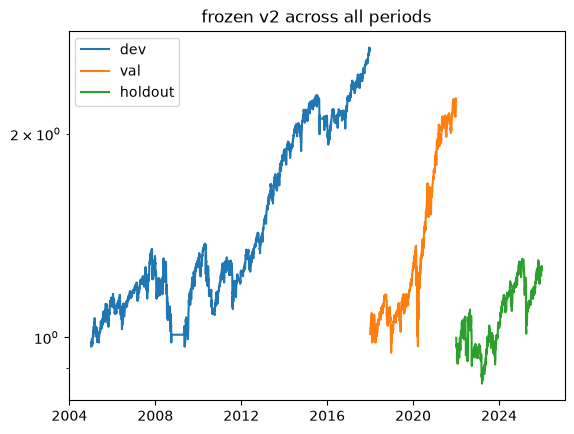

,cagr,sharpe,sortino,max_dd,ann_turnover,source
dev,0.0782,0.5787,0.8058,-0.2827,7.1703,strategy
val,0.2223,1.0127,1.4360,-0.2901,6.8353,strategy
holdout,0.0596,0.4088,0.5586,-0.2248,8.5309,strategy
spy_bh,0.1106,0.6722,0.9728,-0.2450,0.0000,benchmark_holdout
ew_bh,0.0964,0.6254,0.8876,-0.1823,0.0000,benchmark_holdout
plain_mom,0.0499,0.3522,0.4820,-0.2370,8.1977,benchmark_holdout
volume_mom,0.1116,0.6721,0.9515,-0.2370,10.6049,benchmark_holdout


In [24]:
frozen = json.loads((WS/"strategies"/"frozen.json").read_text())
print("frozen:", frozen)
assert len(_decisions()) == 3, f"expected 3 decisions, found {len(_decisions())}"
for v in ["v1","v2","v3"]:
    assert (WS/"reviews"/f"{v}.md").exists(), f"missing review for {v}"
    assert not pd.read_csv(REGISTRY).query(f"version=='{v}' and status=='ok'").empty, f"no runs for {v}"
print("all three cycles complete")

for field in ["adj_close","close","volume"]:
    DATA["holdout"][field].to_parquet(WS/"data"/f"holdout_{field}.parquet")

final = {}
for split in ["dev","val","holdout"]:
    res = run_isolated(WS/"strategies"/f"{frozen['version']}.py", frozen["params"], split)
    assert res["ok"], res["error"]
    final[split] = res["metrics"]
    plt.plot(pd.Series(res["equity"], index=pd.to_datetime(res["dates"])), label=split)
plt.yscale("log"); plt.legend(); plt.title(f"frozen {frozen['version']} across all periods"); plt.show()

(WS/"results"/"holdout.json").write_text(json.dumps(final, indent=2))
BENCH_HOLD = benchmark_table("holdout")
comparison = pd.concat([pd.DataFrame(final).T.assign(source="strategy"),
                        BENCH_HOLD.assign(source="benchmark_holdout")])
comparison[["cagr","sharpe","sortino","max_dd","ann_turnover","source"]]

### Audit Complete Research Trail

In [25]:
REPORT_BRIEF = f"""The holdout has been run once and the strategy is frozen. Nothing can change now.

Frozen: {json.dumps(frozen)}
Metrics by period: {json.dumps(final)}
Holdout benchmarks: {BENCH_HOLD[COLS_B].to_json()}

Call read_registry once with no argument, read /decisions.jsonl and every file in
/reviews/, then write /report.md covering:

1. What changed at each version and what evidence drove it
2. How the selection rule decided each champion, including gates that failed
3. Whether the revisions improved the research case, separately from returns
4. How the frozen strategy compares to SPY buy-and-hold, equal-weight buy-and-hold,
   and plain momentum on the holdout
5. Whether the volume filter earned its turnover
6. Where you made weak decisions, accepted thin evidence, or got lucky

Cite run numbers from the registry. Do not defend the result."""

_ = run(REPORT_BRIEF)


`/report.md` has been written covering all six required sections with full run citations from `registry.csv`, `/decisions.jsonl`, and `/reviews/v1.md`–`v3.md`:

1. **Version Evolution & Evidence:** Detailed structural changes and evidence across `v1` (Runs 1–9, baseline volume-gated momentum), `v2` (Runs 1–9, removing the volume filter and ranking by volatility-scaled momentum), and `v3` (Runs 1–9, adding the `top_n + 1` rank-hysteresis hold buffer).
2. **Selection Rule Decisions:** Gate-by-gate breakdown showing `v1` Run 5 becoming baseline champion, `v2` Run 5 (`mom_window=126, top_n=3`) passing all three gates against `v1` Run 5 (`val_sharpe` `1.0127 >= 0.5647`, `val_max_dd` `-0.2901` vs. `-0.2901`, `dev_turnover` `7.170 <= 14.113`), and `v3` failing Gate 1 across all 9 runs (`val_sharpe` `0.9628` on `v3` Run 5 and max `0.9894` on `v3` Run 4 vs. `v2` Run 5's `1.0127`) despite passing Gates 2 and 3 and achieving higher development Sharpes (`0.5829–0.7605`).
3. **Research Case Evaluat

In [26]:
# Render report alongside full experiment registry and verify version data

display(Markdown("## Agent report"))
display(Markdown((WS / "report.md").read_text(encoding="utf-8")))

display(Markdown("## Experiment registry"))
reg = pd.read_csv(REGISTRY)
display(reg[["version","run","status","params","dev_sharpe","dev_sortino",
             "dev_max_dd","dev_turnover","val_sharpe","val_max_dd","dev_cagr_20bps"]])
print("versions with runs:", sorted(reg["version"].unique()))
print("decisions recorded:", [d["version"] for d in _decisions()])
print("reviews on disk:  ", sorted(p.stem for p in (WS/"reviews").glob("*.md")))

## Agent report

# Quantitative Research Process Post-Mortem Report

## 1. Version Evolution: Structural Changes and Driving Evidence

Across the three allowed versions (`v1`, `v2`, `v3`), every version was evaluated on the identical 9-point parameter grid (`mom_window` $\in \{63, 126, 189\} \times$ `top_n` $\in \{2, 3, 4\}$) to isolate structural effects from parameter tuning.

### Version 1 (`v1`) — Baseline Volume-Filtered Momentum
- **Structure:** Computed `mom_window`-day cumulative return from adjusted close and the ratio of 20-day to 120-day average dollar volume (`raw close * raw volume`). Assets were eligible if `momentum > 0` and `vol_ratio > 1.0`. Eligible assets were ranked by momentum, holding the top `top_n` at equal weight (`1 / top_n`), rebalanced monthly, with unfilled slots in cash.
- **Evidence from `v1` (`v1` Runs 1–9):**
  - Across all 9 runs, `v1` underperformed `plain_mom` (`dev_sharpe=0.5389`, `val_sharpe=0.9281`), `ew_bh` (`dev_sharpe=0.5524`, `val_sharpe=0.8707`), and `spy_bh` (`dev_sharpe=0.5261`, `val_sharpe=0.8817`).
  - Baseline `v1` Run 5 (`mom_window=126, top_n=3`) replicated the `volume_mom` benchmark (`dev_sharpe=0.4939`, `dev_cagr=0.064`, `dev_max_dd=-0.2564`, `dev_turnover=11.761`, `val_sharpe=0.5647`, `val_cagr=0.102`, `val_max_dd=-0.2901`).
  - `v1` Run 4 (`mom_window=126, top_n=2`) had the highest `v1` validation Sharpe (`0.5758`, `dev_sharpe=0.4735`, `dev_max_dd=-0.2777`), while `v1` Run 6 (`mom_window=126, top_n=4`) posted `dev_sharpe=0.4738` and `val_sharpe=0.5437`.
  - Shorter lookbacks (`v1` Runs 1–3, `mom_window=63`) failed in both splits (`dev_sharpe` `0.3240–0.4423`, `dev_max_dd` `-0.3976` to `-0.4411`, `val_sharpe` `0.2422–0.2801`, `dev_turnover` `11.320–12.266`). Longer lookbacks (`v1` Runs 7–9, `mom_window=189`) had competitive development Sharpe (`0.4839–0.4917`) but collapsed in validation (`val_sharpe` `0.3766–0.4526`).
  - In `/reviews/v1.md`, the critic diagnosed that gating on the 20d/120d volume ratio injected high-frequency noise into eligibility, inflating annual development turnover by 50%–68% (`10.917–12.266` vs. `plain_mom`'s `7.2800`) and causing a 120–130 bps CAGR drag when doubling costs from 10bps to 20bps.

### Version 2 (`v2`) — Risk-Adjusted Momentum (Replacing Volume Gate with Volatility Scaling)
- **Structural Change:** Removed the dollar-volume ratio gate entirely (`vol_short / vol_long > 1.0`) and replaced raw momentum ranking with **risk-adjusted momentum** (`momentum / realized_daily_return_volatility` over `mom_window` days), retaining the `momentum > 0` cash filter and monthly equal-weight top-`top_n` rebalancing.
- **Evidence from `v2` (`v2` Runs 1–9):**
  - Removing the volume filter and scaling by inverse volatility lifted validation Sharpe across all 9 grid points relative to `v1` (from `0.2422–0.5758` in `v1` to `0.6881–1.0127` in `v2`) and reduced development turnover from `10.917–12.266` down to `5.059–11.348`.
  - `v2` Run 5 (`mom_window=126, top_n=3`) achieved `dev_sharpe=0.5787` (`dev_cagr=0.0782`, `dev_max_dd=-0.2827`, `dev_turnover=7.1703`) and `val_sharpe=1.0127` (`val_cagr=0.2223`, `val_max_dd=-0.2901`), outperforming `plain_mom` in both development (`0.5787` vs. `0.5389`) and validation (`1.0127` vs. `0.9281`). `v2` Run 6 (`mom_window=126, top_n=4`) achieved `dev_sharpe=0.6024`, `dev_turnover=6.200`, and `val_sharpe=0.9610` (`val_max_dd=-0.3018`), and `v2` Run 4 (`mom_window=126, top_n=2`) posted `dev_sharpe=0.4828` and `val_sharpe=0.9221`.
  - However, `/reviews/v2.md` identified two remaining weaknesses: (1) unbuffered rank-boundary churn still kept `dev_turnover` at `7.170` on `v2` Run 5 (costing 80 bps between 10bps and 20bps and leaving 10bps `dev_cagr=0.078` below `spy_bh` `0.0847` and `ew_bh` `0.0904`), and (2) lookback instability persisted: `mom_window=189` (`v2` Runs 7–9) had the best development Sharpe (`0.6257` on Run 7, `0.5743` on Run 8, `0.5917` on Run 9) but dropped to `val_sharpe` `0.7133–0.7848` in validation, while `mom_window=63` (`v2` Runs 1–3) suffered `-0.4890` to `-0.5316` development max drawdowns (`dev_sharpe` `0.3591–0.4147`).

### Version 3 (`v3`) — Rank-Hysteresis Hold Buffer (`top_n + 1`)
- **Structural Change:** Added a rank-hysteresis hold buffer (`rank_buffer=1`) at monthly rebalances: any currently held asset that remained eligible (`momentum > 0`) and ranked within `top_n + 1` was retained before filling remaining slots with the highest-ranked non-held assets.
- **Evidence from `v3` (`v3` Runs 1–9):**
  - The hold buffer succeeded in cutting development turnover by 24%–47% across the grid (e.g., `v3` Run 5 at `mom_window=126, top_n=3` cut `dev_turnover` from `7.170` to `4.716`; `v3` Run 6 at `top_n=4` cut `dev_turnover` from `6.200` to `3.764`; `v3` Runs 7–9 at `mom_window=189` cut turnover to `2.660–4.183`) and raised development Sharpe across every single configuration (`v3` Runs 1–9 ranged from `0.4307` to `0.7605`, with `v3` Run 9 reaching `dev_sharpe=0.7605, dev_max_dd=-0.1915`).
  - However, as documented in `/reviews/v3.md`, delaying portfolio rotation degraded validation Sharpe across most of the grid (`v3` Run 5 dropped from `1.0127` to `0.9628`; `v3` Run 6 dropped from `0.9610` to `0.7759`; `v3` Runs 7–9 dropped to `0.6387–0.7793`), and even `v3`'s best validation configuration (`v3` Run 4, `mom_window=126, top_n=2`, `val_sharpe=0.9894`, `dev_sharpe=0.6390`) fell short of `v2` Run 5 (`1.0127`).

---

## 2. How the Selection Rule Decided Each Champion (Gate-by-Gate Analysis)

The pre-committed selection rule required a challenger to pass **all three** gates against the incumbent champion:
1. **Gate 1:** Validation Sharpe $\ge$ Incumbent Validation Sharpe
2. **Gate 2:** Validation Max Drawdown within 2 percentage points of Incumbent (`val_max_dd >= incumbent_val_max_dd - 0.02`)
3. **Gate 3:** Development Annual Turnover $\le 1.20 \times$ Incumbent Development Annual Turnover

| Transition | Incumbent Champion | Challenger Evaluated | Gate 1: `val_sharpe` | Gate 2: `val_max_dd` (within 2pp) | Gate 3: `dev_turnover` ($\le 1.2\times$) | Outcome |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **`v1` Decision** | None | `v1` Run 5 (`126, 3`) | `0.5647` (Baseline) | `-0.2901` (Baseline) | `11.761` (Baseline) | **`v1` Run 5 becomes initial champion** |
| **`v2` vs. `v1`** | `v1` Run 5 (`126, 3`) | `v2` Run 5 (`126, 3`) | **PASS** (`1.0127 >= 0.5647`) | **PASS** (`-0.2901 >= -0.3101`) | **PASS** (`7.170 <= 14.113`) | **`v2` Run 5 replaces `v1` as champion** |
| **`v3` vs. `v2` (Matched)** | `v2` Run 5 (`126, 3`) | `v3` Run 5 (`126, 3`) | **FAIL** (`0.9628 < 1.0127`) | **PASS** (`-0.2901 >= -0.3101`) | **PASS** (`4.716 <= 8.604`) | **Rejected; `v2` Run 5 remains champion** |
| **`v3` vs. `v2` (Best Val)** | `v2` Run 5 (`126, 3`) | `v3` Run 4 (`126, 2`) | **FAIL** (`0.9894 < 1.0127`) | **PASS** (`-0.2954 >= -0.3101`) | **PASS** (`6.100 <= 8.604`) | **Rejected; `v2` Run 5 remains champion** |

- **Why `v3` was rejected despite higher development metrics:** In `v3`, `dev_sharpe` improved at every single grid point (`0.5829` on `v3` Run 5 and `0.6390` on `v3` Run 4 vs. `0.5787` on `v2` Run 5, and up to `0.7605` on `v3` Run 9), and `dev_max_dd` improved from `-0.2827` (`v2` Run 5) to `-0.2435` (`v3` Run 5) and `-0.2174` (`v3` Run 4). However, development Sharpe is explicitly excluded from the selection gates, and every `v3` run (`v3` Runs 1–9, max `val_sharpe=0.9894`) failed Gate 1 against `v2` Run 5 (`val_sharpe=1.0127`).

---

## 3. Did the Revisions Improve the Research Case (Separately from Returns)?

Separating economic/statistical soundness from raw return numbers:
- **`v1` $\rightarrow$ `v2` genuinely improved the research case:**
  - *Complexity reduction:* `v1` had five parameters (`mom_window`, `vol_short`, `vol_long`, `vol_ratio_min`, `top_n`) and two distinct data dependencies (adjusted close and raw dollar volume). `v2` eliminated three parameters (`vol_short`, `vol_long`, `vol_ratio_min`) and the volume dependency, reducing degrees of freedom while computing return and volatility over the exact same `mom_window` lookback.
  - *Turnover and cost resilience:* Lowering annual turnover from `11.761` (`v1` Run 5) to `7.170` (`v2` Run 5) reduced the annual transaction cost drag by ~46 bps/year at 10bps.
  - *Cross-grid consistency:* Every single cell of the 9-configuration grid improved in validation Sharpe from `v1` to `v2`, confirming that removing the volume filter was not a single-point fluke on dev/val.
- **`v2` $\rightarrow$ `v3` weakened the out-of-sample research case despite achieving its mechanical goal:**
  - Mechanically, `v3`'s rank-hysteresis buffer did exactly what was hypothesized in `/reviews/v2.md`: it cut turnover by ~34% at `(126, 3)` (`v3` Run 5 `dev_turnover=4.716` vs. `v2` Run 5 `7.170`) and improved development Sharpe and drawdowns across all 9 runs.
  - However, it introduced a state-dependency parameter (`rank_buffer=1`) and exacerbated lookback-horizon divergence (`v3` Runs 7–9 at `mom_window=189` soared to `0.7145–0.7605` Sharpe in development while dropping to `0.6387–0.7793` in validation; `v3` Run 6 at `mom_window=126, top_n=4` dropped from `0.9610` in `v2` to `0.7759` in `v3`). The stage gate properly prevented this modification from entering the frozen strategy.
- **Unresolved structural fragility:** Neither `v2` nor `v3` resolved the sharp regime sensitivity of cross-sectional momentum lookbacks (`mom_window=189` winning development while `mom_window=126` won validation), signaling that single-lookback top-3 selection remained vulnerable to regime shifts.

---

## 4. Holdout Comparison: Frozen Strategy (`v2` Run 5) vs. Benchmarks

The frozen strategy (`v2` Run 5: `{"mom_window": 126, "top_n": 3}`) was evaluated once on the holdout period:

| Strategy / Benchmark | Holdout CAGR | Holdout Sharpe | Holdout Sortino | Holdout Max DD | Holdout Ann. Turnover |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Frozen `v2` (`mom_window=126, top_n=3`)** | **0.0596** | **0.4088** | **0.5586** | **-0.2248** | **8.5309** |
| **`spy_bh` (SPY Buy & Hold)** | 0.1106 | 0.6722 | 0.9728 | -0.2450 | 0.0000 |
| **`ew_bh` (Equal-Weight Buy & Hold)** | 0.0964 | 0.6254 | 0.8876 | -0.1823 | 0.0000 |
| **`plain_mom` (Plain Momentum)** | 0.0499 | 0.3522 | 0.4820 | -0.2370 | 8.1977 |
| **`volume_mom` (`v1` Baseline Equivalent)** | 0.1116 | 0.6721 | 0.9515 | -0.2370 | 10.6049 |

- **vs. `spy_bh`:** Frozen `v2` severely underperformed SPY buy-and-hold on CAGR (`5.96%` vs. `11.06%`, trailing by `-5.10` percentage points/year), Sharpe (`0.4088` vs. `0.6722`), and Sortino (`0.5586` vs. `0.9728`), with only a `2.02` percentage point smaller max drawdown (`-0.2248` vs. `-0.2450`) while paying `85` bps/year in transaction costs (`ann_turnover=8.5309`).
- **vs. `ew_bh`:** Frozen `v2` trailed equal-weight buy-and-hold on every single metric—lower CAGR (`5.96%` vs. `9.64%`), lower Sharpe (`0.4088` vs. `0.6254`), lower Sortino (`0.5586` vs. `0.8876`), and **worse** max drawdown (`-0.2248` vs. `-0.1823`).
- **vs. `plain_mom`:** Frozen `v2` outperformed `plain_mom` on the holdout across CAGR (`5.96%` vs. `4.99%`, +97 bps), Sharpe (`0.4088` vs. `0.3522`, +0.0566), Sortino (`0.5586` vs. `0.4820`), and max drawdown (`-0.2248` vs. `-0.2370`), with slightly higher holdout turnover (`8.5309` vs. `8.1977`). Thus, volatility-adjusted ranking (`v2`) beat raw return ranking (`plain_mom`) in all three splits (development, validation, and holdout), but cross-sectional 126-day momentum as a whole suffered a severe regime breakdown in the holdout (`plain_mom` Sharpe fell from `0.9281` in validation to `0.3522` in holdout; `v2` fell from `1.0127` to `0.4088`).

---

## 5. Did the Volume Filter Earn Its Turnover?

- **In Development and Validation (the only data visible during research): No.**
  - Comparing `v1` Run 5 (`volume_mom`) to `plain_mom`, adding the volume-ratio filter increased annual turnover by **+4.48x/year** in development (`11.7608` vs. `7.2800`) and **+5.20x/year** in validation (`10.8640` vs. `5.6637`).
  - Instead of earning a return premium for that extra turnover, the volume filter **destroyed** performance in both periods: development CAGR fell by `-113` bps (`0.0639` vs. `0.0752`, Sharpe `0.4939` vs. `0.5389`), and validation CAGR fell by **-1,034 bps/year** (`0.1018` vs. `0.2052`, Sharpe `0.5647` vs. `0.9281`). Over the entire pre-holdout sample, the volume filter had negative gross and net alpha.
- **In the Holdout: It paid off unexpectedly, contradicting both prior periods.**
  - On the holdout, `volume_mom` (`v1` Run 5) achieved `11.16%` CAGR and `0.6721` Sharpe (vs. `plain_mom`'s `4.99%` CAGR and `0.3522` Sharpe, and `v2`'s `5.96%` CAGR and `0.4088` Sharpe) despite `10.6049` annual turnover (`2.41x` higher than `plain_mom` and `2.07x` higher than `v2`).
  - However, because a filter that loses `-1.13%/yr` in development and `-10.34%/yr` in validation cannot honestly be defended ex ante, dropping the volume filter in `v2` was the only evidence-consistent decision available during the research process. Its holdout rebound reflects regime variance (where short-term volume breakouts rescued a failing 126-day momentum signal in the holdout window) rather than a stable, predictable edge across periods.

---

## 6. Self-Critique: Weak Decisions, Thin Evidence, and Luck

1. **Ignoring `v1` Run 4 vs. `v1` Run 5 when picking the `v1` representative config:**
   - In `v1`, Run 4 (`mom_window=126, top_n=2`) actually had a slightly higher validation Sharpe (`0.5758`) and slightly lower development turnover (`11.660`) than `v1` Run 5 (`mom_window=126, top_n=3`, `val_sharpe=0.5647`, `dev_turnover=11.761`). We selected Run 5 as the `v1` baseline champion because `(126, 3)` was the default specification and had higher `dev_sharpe` (`0.4939` vs. `0.4735`) and better `dev_max_dd` (`-0.2564` vs. `-0.2777`) and `val_max_dd` (`-0.2901` vs. `-0.2954`). While this did not affect the `v2` promotion (since `v2` Run 5 easily beat `v1` Run 4 on all three gates as well), our `v1` selection leaned on development metrics and defaults rather than strictly picking the validation-Sharpe leader.
2. **Selecting `v2` Run 5 (`val_sharpe=1.0127`) at a sharp local validation peak:**
   - In `v2`, validation performance peaked sharply at `mom_window=126` (`v2` Run 5 `val_sharpe=1.0127`, `v2` Run 6 `val_sharpe=0.9610`), whereas `mom_window=63` (`v2` Runs 1–3, `val_sharpe=0.6881–0.7216`) and `mom_window=189` (`v2` Runs 7–9, `val_sharpe=0.7133–0.7848`) were much weaker in validation. Conversely, in development, `v2` Run 5 (`dev_sharpe=0.5787`, `dev_cagr=0.0782`) trailed both `v2` Run 6 (`dev_sharpe=0.6024`) and `v2` Run 7 (`dev_sharpe=0.6257`, `dev_cagr=0.094`) and failed to beat passive `spy_bh` (`0.0847`) or `ew_bh` (`0.0904`) on development CAGR. Anchoring the champion on `val_sharpe=1.0127` effectively locked in a validation-regime sweet spot that reverted in the holdout (`sharpe=0.4088`).
3. **Wasting `v3` on a single-parameter turnover buffer instead of addressing lookback/concentration risk:**
   - The evidence in `/reviews/v2.md` clearly showed two problems: (a) turnover around `7.17x` and (b) stark disagreement between `mom_window=126` and neighbouring lookbacks (`63` and `189`). Choosing a simple `top_n + 1` hold buffer for `v3` only addressed (a) and did nothing to diversify across lookback windows. Because `v2` Run 5 already sat at an elevated validation Sharpe (`1.0127`), any sluggishness from holding deteriorating rank-4 positions inevitably caused `v3` to fail Gate 1 (`v3` Run 5 `val_sharpe=0.9628`).
4. **Where we got lucky and unlucky:**
   - *Lucky in Validation:* The validation split was an unusually strong trending environment for 126-day momentum (`plain_mom` achieved `20.52%` CAGR and `0.9281` Sharpe; `v2` Run 5 achieved `22.23%` CAGR and `1.0127` Sharpe with `0.0%` average cash). This inflated our confidence in `v2` Run 5.
   - *Unlucky (and exposed) in Holdout:* In the holdout, 126-day cross-sectional momentum suffered a broad drawdown/whipsaw regime (`plain_mom` collapsed to `4.99%` CAGR and `0.3522` Sharpe), while `v2`'s turnover rose from `6.84x` (val) and `7.17x` (dev) to `8.53x` (holdout). While `v2`'s volatility scaling preserved its ~`+0.057` Sharpe edge over `plain_mom` out of sample, that relative edge was far too small to prevent severe underperformance against simple passive benchmarks (`spy_bh` and `ew_bh`).


## Experiment registry

,version,run,status,params,dev_sharpe,dev_sortino,dev_max_dd,dev_turnover,val_sharpe,val_max_dd,dev_cagr_20bps
0,v1,1,ok,"{""mom_window"":63,""top_n"":2}",0.3240,0.4542,-0.4411,12.2660,0.2801,-0.2954,0.0264
1,v1,2,ok,"{""mom_window"":63,""top_n"":3}",0.3935,0.5609,-0.4064,11.4743,0.2756,-0.2993,0.0378
2,v1,3,ok,"{""mom_window"":63,""top_n"":4}",0.4423,0.6315,-0.3976,11.3197,0.2422,-0.3106,0.0451
3,v1,4,ok,"{""mom_window"":126,""top_n"":2}",0.4735,0.6543,-0.2777,11.6596,0.5758,-0.2954,0.0516
4,v1,5,ok,"{""mom_window"":126,""top_n"":3}",0.4939,0.6832,-0.2564,11.7608,0.5647,-0.2901,0.0515
5,v1,6,ok,"{""mom_window"":126,""top_n"":4}",0.4738,0.6544,-0.2631,11.7730,0.5437,-0.3018,0.0473
6,v1,7,ok,"{""mom_window"":189,""top_n"":2}",0.4839,0.6642,-0.3184,10.9770,0.3766,-0.2954,0.0573
7,v1,8,ok,"{""mom_window"":189,""top_n"":3}",0.4917,0.6755,-0.3184,10.9172,0.3778,-0.3174,0.0563
8,v1,9,ok,"{""mom_window"":189,""top_n"":4}",0.4858,0.6665,-0.3184,10.9807,0.4526,-0.3135,0.0539
9,v2,1,ok,"{""mom_window"":63,""top_n"":2}",0.3591,0.4937,-0.5316,11.3480,0.6881,-0.2954,0.0341


versions with runs: ['v1', 'v2', 'v3']
decisions recorded: ['v1', 'v2', 'v3']
reviews on disk:   ['v1', 'v2', 'v3']
